In [9]:
from Model import Minimizer, UFloat, Levels
import numpy as np
import pandas as pd
from Model.utilities import n_, s_
from tqdm.auto import tqdm
from PlotUtils.saveToCsv import saveToCsv, getNextFilename
import re
from PlotUtils import confel

from PlotUtils import errsPlot as plt, splt

splt.set_export_folder(".")

In [10]:
n_g = 2.687e25
T_g = 285

In [11]:
original_filename = '013'
# original_filename = '108'

data = pd.read_csv( f"Densities/{original_filename}.csv", index_col = False).to_dict('list')

data['density'] = [ UFloat.UFloat( n, s ) for n, s in zip( data['density_n'], data['density_s'] ) ]
data['label_idx'] = Levels.Levels().namesToIdxs( data['level'] )

In [12]:
reps = 1000
results = []

for i in tqdm( range( reps ) ):
    results.append( Minimizer.Minimizer().fit( data['density'], data['label_idx'], howmany=1, f_e_guess = 0.001, T_e_guess = 0.3 ) )

  0%|          | 0/1000 [00:00<?, ?it/s]

In [13]:
saveToCsv( { 'f_e': [ x[0] for x in results ], 'T_e': [ x[1] for x in results ] }, basename = f"Densities_fit/{original_filename}_fit" )

Saved as Densities_fit/013_fit001


'Densities_fit/013_fit001'

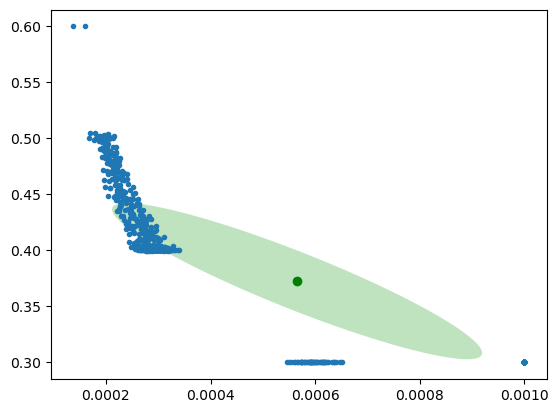

In [14]:
plt.plot( *np.mean( results, axis = 0), 'go', label = 'Average +/- 1 std' )
confel.confidence_ellipse( results )
for x,y in results:
    plt.plot( x,y, '.', color='tab:blue' )

# plt.xlabel("f_e")
# plt.ylabel("T_e [eV]")

# splt.export( filename + "_differentresults" )